<a href="https://colab.research.google.com/github/Ascavalc/Floripa/blob/main/Aula_15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 15 — Grupos e comunidades nas redes sociais

Vamos investigar uma rede social fictícia. O **K-means** reúne usuários com comportamentos semelhantes. Depois, o **Louvain** procura comunidades nas conexões entre essas mesmas contas.

Trabalharemos com **50.000 usuários**, **120.000 publicações contabilizadas nos perfis** e **250.000 eventos de interação** em uma janela de 30 dias. As bases são simuladas e contêm algumas ausências e erros de registro para o exercício de preparação. Não representam usuários de uma plataforma real.

Coloque os dois CSVs na mesma pasta do notebook. No Google Colab, a célula de leitura solicitará os arquivos se eles ainda não estiverem disponíveis. Execute as células na ordem. A etapa de entrada de novos dados pedirá seis valores.

## 1. Bibliotecas e leitura

Usaremos `KMeans` para os agrupamentos, `PCA` para o gráfico em duas dimensões e `networkx` para analisar as conexões. Se alguma biblioteca estiver ausente, execute a instalação indicada abaixo.

In [1]:
# Execute somente se houver erro de biblioteca não encontrada.
# %pip install pandas numpy matplotlib scikit-learn networkx

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display, Markdown
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from threadpoolctl import threadpool_limits

pd.set_option('display.max_columns', 15)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
CORES = ['#1976D2', '#E39D24', '#249C84', '#A75AA8', '#D85C59', '#536D9C', '#7F8C31', '#805B42']

arquivos = ['Aula_15_Usuarios.csv', 'Aula_15_Interacoes.csv']
if not all(Path(nome).exists() for nome in arquivos):
    try:
        from google.colab import files
        print('Selecione os dois arquivos CSV da aula 15.')
        files.upload()
    except ImportError:
        raise FileNotFoundError('Coloque os dois CSVs na mesma pasta do notebook.')

usuarios_brutos = pd.read_csv(arquivos[0], sep=';', decimal=',', encoding='utf-8-sig')
interacoes_brutas = pd.read_csv(arquivos[1], sep=';', encoding='utf-8-sig')
print(f'Usuários: {len(usuarios_brutos):,} | Interações: {len(interacoes_brutas):,}')
display(usuarios_brutos.head())
display(interacoes_brutas.head())

Usuários: 50,000 | Interações: 250,000


,usuario_id,publicacoes_30d,comentarios_30d,compartilhamentos_30d,curtidas_recebidas_30d,respostas_recebidas_30d,diversidade_temas,frequencia_semanal,interacoes_por_publicacao,horario_predominante
0,U00001,0,0.00,0,0.00,0,1.00,3.00,NaN,Noite
1,U00002,0,1.00,4,0.00,0,6.00,5.00,NaN,Madrugada
2,U00003,6,0.00,1,2.00,3,3.00,6.00,0.83,Manhã
3,U00004,1,0.00,0,1.00,4,2.00,1.00,5.00,Manhã
4,U00005,8,0.00,0,1.00,4,2.00,6.00,0.62,Noite


,interacao_id,usuario_origem,usuario_destino,tipo_interacao
0,I000001,U39570,U17288,curtida
1,I000002,U02564,U40751,curtida
2,I000003,U43031,U04411,compartilhamento
3,I000004,U47055,U28819,menção
4,I000005,U28365,U26922,compartilhamento


Cada linha da primeira tabela descreve um usuário. A segunda registra um evento de uma conta para outra. Duas contas podem interagir várias vezes, portanto repetir um par de usuários não significa duplicação indevida.

| Coluna dos perfis | Significado |
|---|---|
| `usuario_id` | Código fictício. Serve para relacionar as tabelas. |
| `publicacoes_30d` | Publicações feitas pelo usuário em 30 dias. |
| `comentarios_30d` | Comentários feitos em publicações de outras contas. |
| `compartilhamentos_30d` | Compartilhamentos realizados. |
| `curtidas_recebidas_30d` | Curtidas recebidas nas próprias publicações. |
| `respostas_recebidas_30d` | Comentários recebidos nas próprias publicações. |
| `diversidade_temas` | Quantidade de temas registrados no período, de 1 a 12 nesta simulação. Não informa quais temas são esses. |
| `frequencia_semanal` | Frequência típica de atividade, de 0 a 7 dias por semana. |
| `interacoes_por_publicacao` | Curtidas e respostas recebidas, divididas pelo número de publicações. Fica ausente quando não há publicação. |
| `horario_predominante` | Período mais frequente de atividade. |

Na tabela de interações, `interacao_id` identifica o evento, `usuario_origem` indica quem interagiu e `usuario_destino` indica quem recebeu a interação. `tipo_interacao` distingue comentário, compartilhamento, curtida e menção.

## 2. Inspeção e formatação

Primeiro, verificamos os tipos, as ausências e as duplicações. Não usamos o identificador como uma medida numérica. Um código maior não representa uma pessoa mais ativa.

In [3]:
usuarios = usuarios_brutos.copy()
usuarios.columns = usuarios.columns.str.strip()
usuarios['usuario_id'] = usuarios['usuario_id'].astype('string').str.strip().str.upper()
usuarios = usuarios.dropna(subset=['usuario_id'])
usuarios = usuarios[usuarios['usuario_id'].ne('')].drop_duplicates('usuario_id').reset_index(drop=True)

numericas = ['publicacoes_30d', 'comentarios_30d', 'compartilhamentos_30d',
             'curtidas_recebidas_30d', 'respostas_recebidas_30d', 'diversidade_temas',
             'frequencia_semanal', 'interacoes_por_publicacao']
for coluna in numericas:
    usuarios[coluna] = pd.to_numeric(usuarios[coluna], errors='coerce')
usuarios[numericas] = usuarios[numericas].replace([np.inf, -np.inf], np.nan)
resumo_ausencias = pd.DataFrame({'Tipo': usuarios.dtypes.astype(str),
                               'Ausentes': usuarios.isna().sum(),
                               'Ausentes (%)': usuarios.isna().mean() * 100})
display(resumo_ausencias)
print('IDs repetidos na origem:', usuarios_brutos['usuario_id'].duplicated().sum())

,Tipo,Ausentes,Ausentes (%)
usuario_id,string,0,0.00
publicacoes_30d,int64,0,0.00
comentarios_30d,float64,0,0.00
compartilhamentos_30d,int64,0,0.00
curtidas_recebidas_30d,float64,500,1.00
respostas_recebidas_30d,int64,0,0.00
diversidade_temas,float64,2500,5.00
frequencia_semanal,float64,1000,2.00
interacoes_por_publicacao,float64,24935,49.87
horario_predominante,object,0,0.00


IDs repetidos na origem: 0


## 3. Valores inválidos, distribuição e cauda longa

Uma contagem negativa é um erro. Uma frequência de nove dias por semana também é impossível. Vamos transformar esses valores em ausências antes de preencher os campos usados no modelo.

Um valor alto, por outro lado, pode ser verdadeiro. O boxplot sinaliza observações afastadas, mas não decide quais devemos excluir. Em redes sociais, uma pequena parcela das contas costuma concentrar mais atividade. Nesta simulação, preservaremos as contagens altas que respeitam o significado da variável.

,Valores inválidos tratados
publicacoes_30d,0
comentarios_30d,12
compartilhamentos_30d,0
curtidas_recebidas_30d,0
respostas_recebidas_30d,0
frequencia_semanal,12
diversidade_temas,8


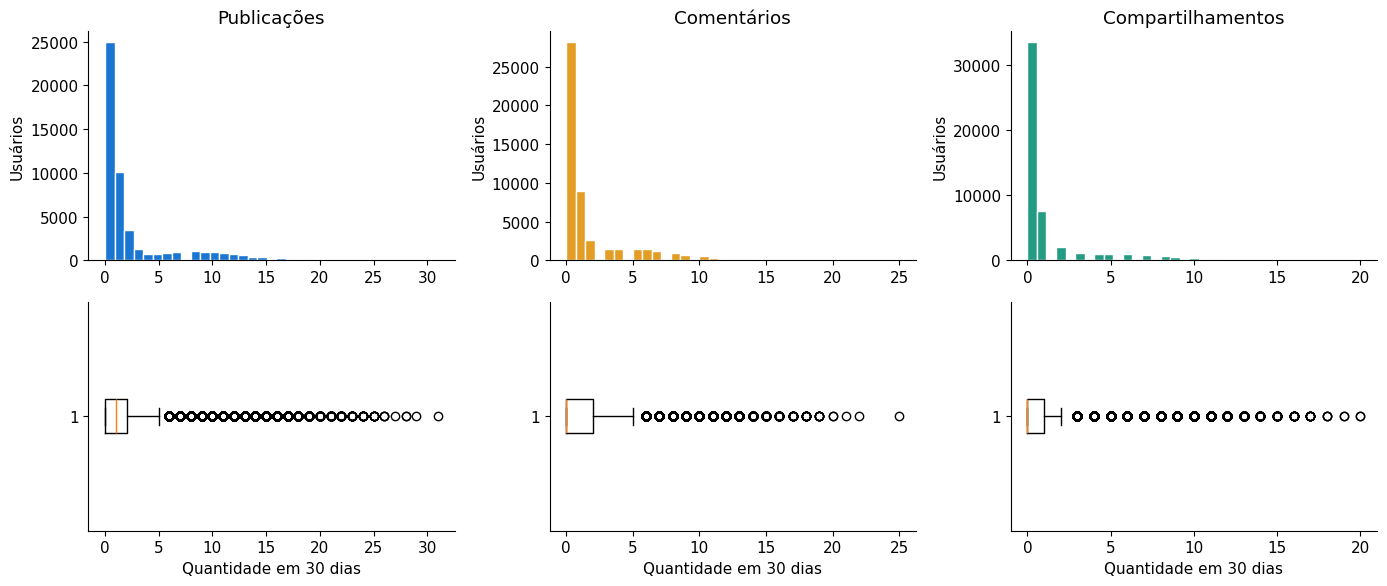

,Limite superior do boxplot,Registros acima do limite
publicacoes_30d,5.00,8743
comentarios_30d,5.00,5774
compartilhamentos_30d,2.50,6914


In [4]:
contagens = ['publicacoes_30d', 'comentarios_30d', 'compartilhamentos_30d',
            'curtidas_recebidas_30d', 'respostas_recebidas_30d']
invalidos = {}
for coluna in contagens:
    mascara = usuarios[coluna].notna() & ((usuarios[coluna] < 0) | (usuarios[coluna] % 1 != 0))
    invalidos[coluna] = int(mascara.sum())
    usuarios.loc[mascara, coluna] = np.nan

for coluna, minimo, maximo in [('frequencia_semanal', 0, 7), ('diversidade_temas', 1, 12)]:
    mascara = usuarios[coluna].notna() & (~usuarios[coluna].between(minimo, maximo) | (usuarios[coluna] % 1 != 0))
    invalidos[coluna] = int(mascara.sum())
    usuarios.loc[mascara, coluna] = np.nan
display(pd.Series(invalidos, name='Valores inválidos tratados').to_frame())

colunas_graficos = ['publicacoes_30d', 'comentarios_30d', 'compartilhamentos_30d']
fig, eixos = plt.subplots(2, 3, figsize=(14, 6))
for j, coluna in enumerate(colunas_graficos):
    valores = usuarios[coluna].dropna()
    eixos[0, j].hist(valores, bins=35, color=CORES[j], edgecolor='white')
    eixos[0, j].set_title(['Publicações', 'Comentários', 'Compartilhamentos'][j])
    eixos[0, j].set_ylabel('Usuários')
    eixos[1, j].boxplot(valores, vert=False)
    eixos[1, j].set_xlabel('Quantidade em 30 dias')
plt.tight_layout()
plt.show()

q1 = usuarios[colunas_graficos].quantile(.25)
q3 = usuarios[colunas_graficos].quantile(.75)
limite_superior = q3 + 1.5 * (q3 - q1)
display(pd.DataFrame({'Limite superior do boxplot': limite_superior,
                      'Registros acima do limite': (usuarios[colunas_graficos] > limite_superior).sum()}))

## 4. Preparação das variáveis

Usaremos seis características para descrever o comportamento. As respostas recebidas e a taxa por publicação ficam fora para reduzir a repetição de informação sobre engajamento. O horário permanece como descrição, sem receber uma ordem numérica artificial.

Preenchemos as ausências com a mediana, um valor que representa o meio da distribuição. Nas quatro contagens mais assimétricas, a transformação `log1p` aproxima os valores muito altos dos demais, preservando a ordem. Depois, a padronização coloca as entradas em escalas comparáveis.

Não temos uma coluna com o grupo correto de cada usuário. Avaliaremos se os grupos ficam separados, se apresentam comportamentos distintos e se a divisão se mantém quando repetimos o ajuste. Isso permite julgar a qualidade do agrupamento. Acurácia exigiria uma resposta correta conhecida para comparar com o resultado.

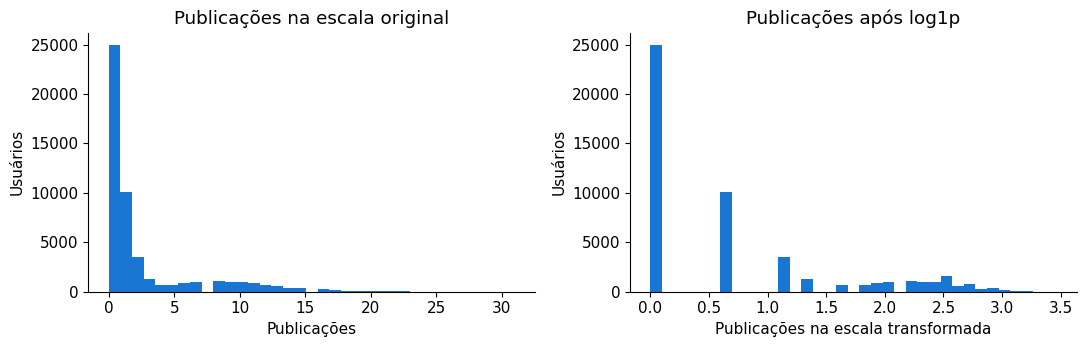

Matriz para o K-means: (50000, 6)
Ausências restantes: 0


In [5]:
variaveis = ['publicacoes_30d', 'comentarios_30d', 'compartilhamentos_30d',
             'curtidas_recebidas_30d', 'diversidade_temas', 'frequencia_semanal']
colunas_log = variaveis[:4]
imputador = SimpleImputer(strategy='median')
dados_modelo = pd.DataFrame(imputador.fit_transform(usuarios[variaveis]), columns=variaveis)
dados_transformados = dados_modelo.copy()
dados_transformados[colunas_log] = np.log1p(dados_transformados[colunas_log])
padronizador = StandardScaler()
X = padronizador.fit_transform(dados_transformados)

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.6))
eixos[0].hist(dados_modelo['publicacoes_30d'], bins=35, color=CORES[0])
eixos[0].set(title='Publicações na escala original', xlabel='Publicações', ylabel='Usuários')
eixos[1].hist(dados_transformados['publicacoes_30d'], bins=35, color=CORES[0])
eixos[1].set(title='Publicações após log1p', xlabel='Publicações na escala transformada', ylabel='Usuários')
plt.tight_layout()
plt.show()
print('Matriz para o K-means:', X.shape)
print('Ausências restantes:', int(np.isnan(X).sum()))

## 5. Como o K-means aprende

Vamos acompanhar seis pontos antes de trabalhar com a base completa. Cada ponto representa um perfil com duas características. As marcas em X são os centros que representam os grupos.

O algoritmo liga cada ponto ao centro mais próximo. Em seguida, desloca cada centro para o meio dos pontos que recebeu. Como o centro mudou de lugar, algum ponto pode ficar mais próximo de outro grupo na rodada seguinte. O processo se repete até as mudanças ficarem pequenas.

Compare as três imagens da esquerda para a direita. Observe principalmente o ponto C e o deslocamento dos centros. No modelo completo, o computador fará esse mesmo trabalho com as seis características ao mesmo tempo.

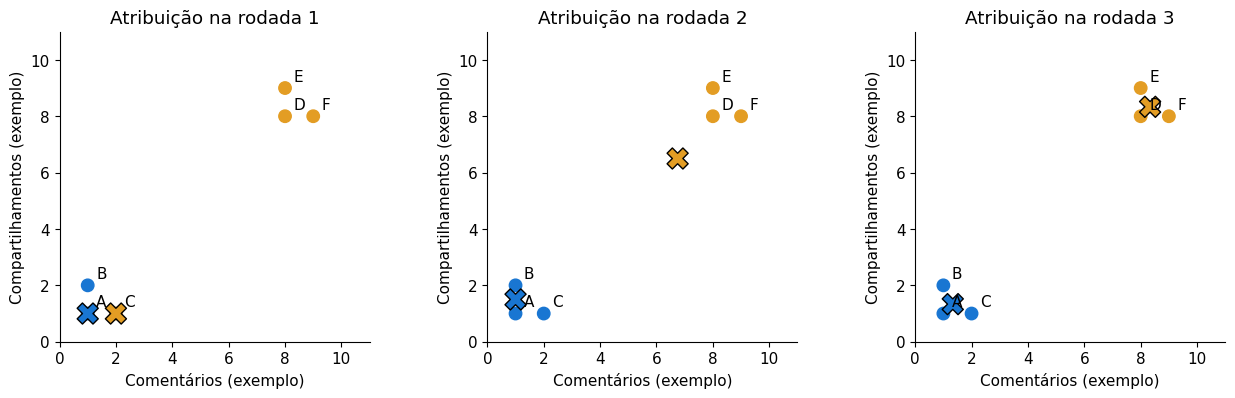

In [6]:
exemplo = np.array([[1, 1], [1, 2], [2, 1], [8, 8], [8, 9], [9, 8]], dtype=float)
centros = np.array([[1, 1], [2, 1]], dtype=float)
etapas = []
for rodada in range(3):
    distancias = np.linalg.norm(exemplo[:, None, :] - centros[None, :, :], axis=2)
    grupos = distancias.argmin(axis=1)
    etapas.append((centros.copy(), grupos.copy()))
    centros = np.array([exemplo[grupos == g].mean(axis=0) for g in range(2)])

fig, eixos = plt.subplots(1, 3, figsize=(13, 4))
for rodada, (centros_da_rodada, grupos) in enumerate(etapas):
    ax = eixos[rodada]
    ax.scatter(exemplo[:, 0], exemplo[:, 1], c=[CORES[g] for g in grupos], s=80)
    ax.scatter(centros_da_rodada[:, 0], centros_da_rodada[:, 1], c=CORES[:2], marker='X', s=230, edgecolors='black')
    for letra, (x, y) in zip('ABCDEF', exemplo):
        ax.annotate(letra, (x, y), xytext=(6, 5), textcoords='offset points')
    ax.set(title=f'Atribuição na rodada {rodada + 1}', xlabel='Comentários (exemplo)',
           ylabel='Compartilhamentos (exemplo)', xlim=(0, 11), ylim=(0, 11))
    ax.set_aspect('equal')
plt.tight_layout()
plt.show()

O ponto C muda de grupo quando os centros se deslocam. No final, cada centro representa o perfil médio dos pontos que ficaram com ele. Nenhum registro precisa estar exatamente sobre o centro.

## 6. Quantidade de grupos

Vamos experimentar de dois a oito grupos, mantendo as mesmas variáveis e o mesmo tratamento. Precisamos escolher uma divisão que separe diferenças importantes sem criar grupos demais.

**Como ler o cotovelo.** O eixo horizontal mostra quantos grupos criamos. O vertical mostra a inércia, uma medida de quanto os registros ficam espalhados ao redor dos centros. A curva costuma descer quando acrescentamos grupos. Procure a mudança entre uma queda forte e uma queda mais suave. Essa mudança sugere que os grupos adicionais começaram a trazer menos ganho. O menor ponto da curva, sozinho, não decide a escolha.

**Como ler a silhueta.** O eixo horizontal continua mostrando a quantidade de grupos. No vertical, quanto maior a silhueta, melhor a separação nessa medida. Um registro próximo de 1 combina bem com seu grupo e está distante dos outros. Próximo de zero, fica na fronteira entre grupos. Abaixo de zero, está, em média, mais próximo de outro grupo. A média resume essa situação para o conjunto avaliado.

O modelo usará todos os usuários. Para agilizar a avaliação, calcularemos a silhueta na mesma amostra de 3.000 usuários em todas as opções. Assim, a comparação usa os mesmos registros. O valor é uma estimativa para a base completa, e não uma porcentagem de acertos.

,K,Inércia,Silhueta
0,2,180375.05,0.41
1,3,114237.27,0.49
2,4,75550.27,0.54
3,5,67457.77,0.50
4,6,60526.29,0.43
5,7,55267.69,0.40
6,8,50021.38,0.39


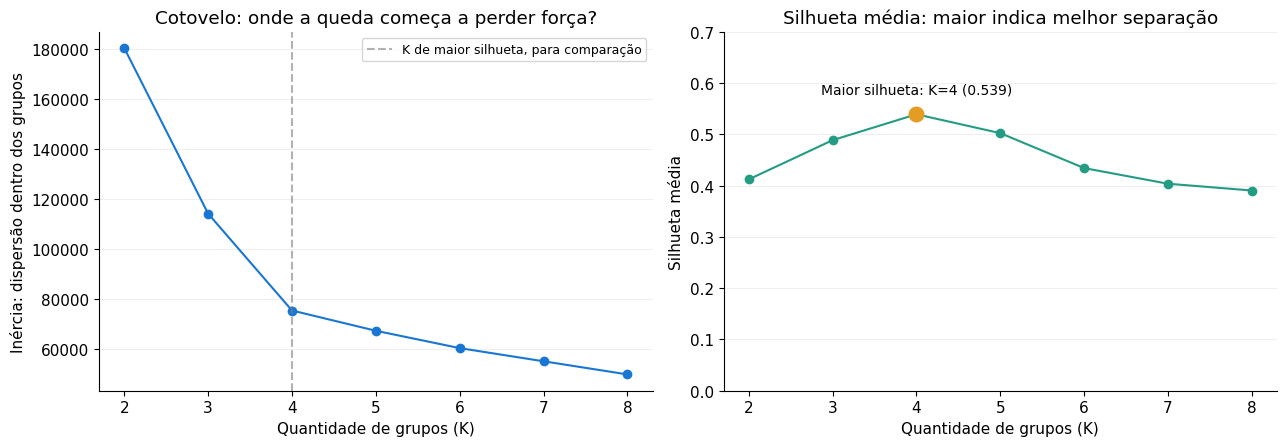

In [7]:
indices_avaliacao = np.random.default_rng(42).choice(len(X), size=min(3000, len(X)), replace=False)
modelos = {}
avaliacoes = []
with threadpool_limits(limits=2):
    for k in range(2, 9):
        modelo = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
        rotulos = modelo.fit_predict(X)
        silhueta = silhouette_score(X[indices_avaliacao], rotulos[indices_avaliacao])
        modelos[k] = modelo
        avaliacoes.append({'K': k, 'Inércia': modelo.inertia_, 'Silhueta': silhueta})
avaliacao = pd.DataFrame(avaliacoes)
display(avaliacao.round(3))

k_candidato = int(avaliacao.loc[avaliacao['Silhueta'].idxmax(), 'K'])
melhor_linha = avaliacao.set_index('K').loc[k_candidato]
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.6))
eixos[0].plot(avaliacao['K'], avaliacao['Inércia'], 'o-', color=CORES[0])
eixos[0].set(title='Cotovelo: onde a queda começa a perder força?',
             xlabel='Quantidade de grupos (K)', ylabel='Inércia: dispersão dentro dos grupos')
eixos[0].axvline(k_candidato, ls='--', color='gray', alpha=.6,
                 label='K de maior silhueta, para comparação')
eixos[0].legend(fontsize=9)
eixos[1].plot(avaliacao['K'], avaliacao['Silhueta'], 'o-', color=CORES[2])
eixos[1].scatter([k_candidato], [melhor_linha['Silhueta']], s=110, color=CORES[1], zorder=3)
eixos[1].annotate(f"Maior silhueta: K={k_candidato} ({melhor_linha['Silhueta']:.3f})",
                 (k_candidato, melhor_linha['Silhueta']), xytext=(0, 15),
                 textcoords='offset points', ha='center', fontsize=10)
eixos[1].set(title='Silhueta média: maior indica melhor separação',
             xlabel='Quantidade de grupos (K)', ylabel='Silhueta média', ylim=(0, .7))
for ax in eixos:
    ax.set_xticks(avaliacao['K'])
    ax.grid(axis='y', alpha=.2)
plt.tight_layout()
plt.show()

### Leitura dos gráficos desta execução

No cotovelo, a inércia cai bastante até **quatro grupos**. Depois desse ponto, as reduções ficam menores. Essa mudança de inclinação favorece investigar quatro grupos. A linha tracejada marca o K de maior silhueta para facilitar a comparação entre os gráficos, sem detectar automaticamente um cotovelo.

Na silhueta, quatro grupos também apresentam a maior média: **0,539**. Com cinco grupos, ela cai para **0,502**. Criar um grupo a mais reduziu a inércia, mas piorou a separação por essa medida. Por isso, seguiremos com quatro e examinaremos seus perfis.

Esses gráficos favorecem uma opção entre as que testamos. Para dizer se ela ficou boa, ainda vamos verificar cada grupo e repetir o ajuste.

## 7. Interpretação dos grupos

A opção de maior silhueta será o nosso ponto de partida. Ainda precisamos conferir o significado dos grupos: uma separação matemática só ajuda a análise quando conseguimos explicar o que diferencia seus integrantes.

Na tabela, cada linha será um grupo e cada coluna manterá a unidade original. Compare uma característica de cada vez. Depois, reúna as diferenças para descrever o perfil do grupo. Os números 1, 2, 3 e 4 servem apenas para identificar os grupos.

,publicacoes_30d,comentarios_30d,compartilhamentos_30d,curtidas_recebidas_30d,diversidade_temas,frequencia_semanal
grupo_kmeans,,,,,,
1,0.85,0.63,5.95,0.89,6.80,5.30
2,0.96,6.10,0.54,0.98,5.37,5.78
3,0.21,0.17,0.08,0.25,1.71,1.77
4,9.51,0.56,0.36,4.02,2.99,5.92


,Usuários
grupo_kmeans,
1,7357
2,10789
3,21457
4,10397


K escolhido para a interpretação: 4


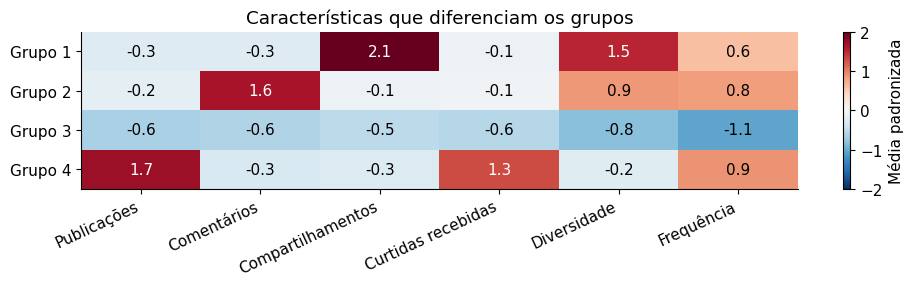

In [8]:
k_escolhido = int(avaliacao.loc[avaliacao['Silhueta'].idxmax(), 'K'])
modelo_kmeans = modelos[k_escolhido]
resultado = usuarios.copy()
resultado[variaveis] = dados_modelo
resultado['grupo_kmeans'] = modelo_kmeans.labels_ + 1
perfil_grupos = resultado.groupby('grupo_kmeans')[variaveis].mean()
tamanho_grupos = resultado['grupo_kmeans'].value_counts().sort_index()
display(perfil_grupos.round(2))
display(tamanho_grupos.rename('Usuários').to_frame())
print('K escolhido para a interpretação:', k_escolhido)

# A tabela acima mantém as unidades originais. O gráfico compara diferenças de escala.
medias_padronizadas = pd.DataFrame(X, columns=variaveis).groupby(modelo_kmeans.labels_ + 1).mean()
fig, ax = plt.subplots(figsize=(10, max(3, .65 * k_escolhido)))
imagem = ax.imshow(medias_padronizadas, cmap='RdBu_r', vmin=-2, vmax=2, aspect='auto')
ax.set_xticks(range(len(variaveis)), ['Publicações', 'Comentários', 'Compartilhamentos', 'Curtidas recebidas', 'Diversidade', 'Frequência'], rotation=25, ha='right')
ax.set_yticks(range(k_escolhido), [f'Grupo {i}' for i in medias_padronizadas.index])
for i in range(k_escolhido):
    for j in range(len(variaveis)):
        valor = medias_padronizadas.iloc[i, j]
        ax.text(j, i, f'{valor:.1f}', ha='center', va='center', color='white' if abs(valor) > 1.2 else 'black')
fig.colorbar(imagem, ax=ax, label='Média padronizada')
ax.set_title('Características que diferenciam os grupos')
plt.tight_layout()
plt.show()

### 7.1. A média esconde algum grupo mal separado?

A silhueta média pode parecer favorável mesmo quando um dos grupos tem dificuldades. Vamos olhar os usuários separadamente e depois resumir os valores por grupo.

No gráfico, cada faixa colorida reúne os usuários de um grupo, ordenados pela silhueta. O avanço para a direita indica melhor separação. Trechos à esquerda do zero pedem atenção, pois esses usuários estão mais próximos de outro grupo. A linha tracejada marca a média geral. Uma faixa mais alta contém mais usuários na amostra, e não representa melhor qualidade.

A tabela mostra também a parcela de silhuetas negativas. Essa porcentagem mede casos que merecem revisão pela distância. Ela não é uma taxa de erro de classificação.

,Usuários na amostra,Silhueta média,Silhueta mediana,Silhuetas negativas (%)
Grupo,,,,
1,430,0.44,0.47,0.70
2,670,0.39,0.42,0.45
3,1280,0.68,0.72,0.00
4,620,0.49,0.53,0.65


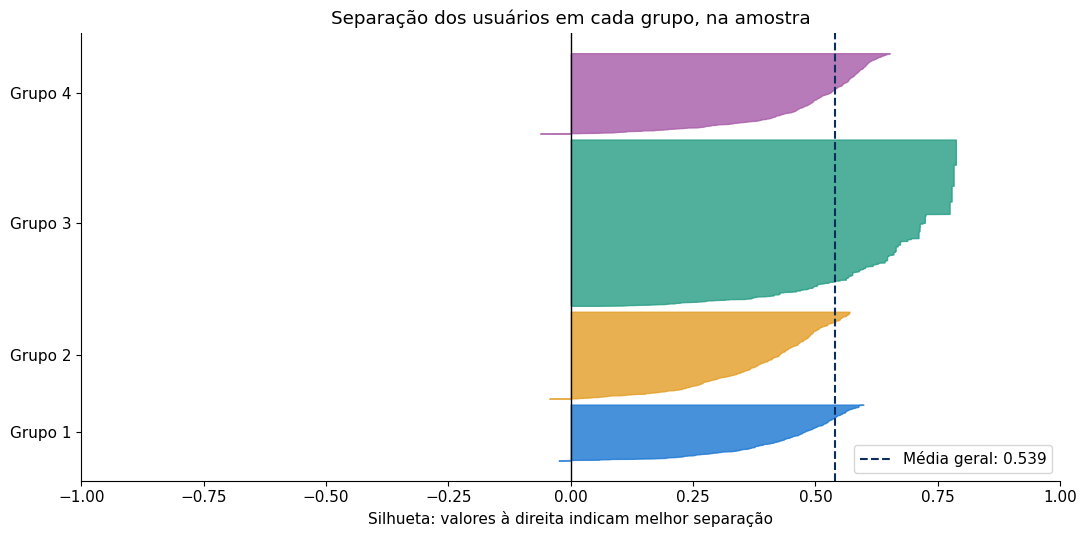

In [9]:
rotulos_amostra = modelo_kmeans.labels_[indices_avaliacao]
with threadpool_limits(limits=2):
    silhuetas = silhouette_samples(X[indices_avaliacao], rotulos_amostra)
detalhe_silhueta = pd.DataFrame({'Grupo': rotulos_amostra + 1, 'Silhueta': silhuetas})
resumo_silhueta = detalhe_silhueta.groupby('Grupo').agg(
    Usuarios_na_amostra=('Silhueta', 'size'),
    Silhueta_media=('Silhueta', 'mean'),
    Silhueta_mediana=('Silhueta', 'median'),
    Negativas_pct=('Silhueta', lambda valores: (valores < 0).mean() * 100))
display(resumo_silhueta.rename(columns={
    'Usuarios_na_amostra': 'Usuários na amostra', 'Silhueta_media': 'Silhueta média',
    'Silhueta_mediana': 'Silhueta mediana', 'Negativas_pct': 'Silhuetas negativas (%)'}).round(3))

fig, ax = plt.subplots(figsize=(11, 5.5))
inicio = 0
marcas, nomes = [], []
for grupo in range(1, k_escolhido + 1):
    valores = np.sort(detalhe_silhueta.loc[detalhe_silhueta['Grupo'] == grupo, 'Silhueta'])
    fim = inicio + len(valores)
    ax.fill_betweenx(np.arange(inicio, fim), 0, valores, color=CORES[grupo - 1], alpha=.8)
    marcas.append((inicio + fim) / 2)
    nomes.append(f'Grupo {grupo}')
    inicio = fim + 45
ax.axvline(0, color='black', lw=1)
ax.axvline(silhuetas.mean(), color='#0A2D5B', ls='--', label=f'Média geral: {silhuetas.mean():.3f}')
ax.set(yticks=marcas, yticklabels=nomes, xlim=(-1, 1),
       xlabel='Silhueta: valores à direita indicam melhor separação',
       title='Separação dos usuários em cada grupo, na amostra')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

### 7.2. Os grupos se mantêm quando repetimos a análise?

Vamos ajustar três novos modelos, cada um com 80% dos usuários escolhidos ao acaso. Depois, pediremos que cada modelo atribua um grupo aos mesmos 50 mil usuários. Se a divisão mudar pouco, teremos evidência de estabilidade.

Para comparar as divisões, usaremos a **concordância ajustada, chamada ARI**. Próximo de 1, os modelos mantêm praticamente os mesmos usuários juntos. Próximo de zero, a concordância se aproxima do esperado ao acaso. O ARI reconhece que trocar o nome “grupo 1” por “grupo 3” não muda quem está junto.

Neste teste, mantemos a preparação dos dados já aprendida. Verificamos a estabilidade do agrupamento nessa representação. Não estamos medindo acurácia, nem desempenho em uma população futura.

In [10]:
repeticoes = []
with threadpool_limits(limits=2):
    for rodada, semente in enumerate([7, 21, 84], start=1):
        indices = np.random.default_rng(semente).choice(len(X), int(.8 * len(X)), replace=False)
        modelo_repetido = KMeans(n_clusters=k_escolhido, n_init=10, random_state=semente)
        modelo_repetido.fit(X[indices])
        grupos_repetidos = modelo_repetido.predict(X)
        concordancia = adjusted_rand_score(modelo_kmeans.labels_, grupos_repetidos)
        repeticoes.append({'Repetição': rodada, 'Usuários no ajuste': len(indices),
                           'Concordância com a divisão original (ARI)': concordancia})
estabilidade_kmeans = pd.DataFrame(repeticoes)
display(estabilidade_kmeans.round(4))

,Repetição,Usuários no ajuste,Concordância com a divisão original (ARI)
0,1,40000,1.00
1,2,40000,1.00
2,3,40000,1.00


### 7.3. Conclusão sobre o K-means

**O agrupamento teve boa qualidade para descrever os comportamentos desta base simulada.** Essa conclusão reúne a separação observada, a estabilidade nas repetições e as diferenças que conseguimos interpretar nos perfis.

| Evidência desta execução | Como interpretar |
|---|---|
| Quatro grupos e silhueta média de **0,539** | Foi a melhor separação entre as opções de dois a oito grupos. O cotovelo também favoreceu examinar essa quantidade. |
| **0,33%** dos usuários da amostra com silhueta negativa | Poucos casos ficaram, em média, mais próximos de outro grupo. Esse percentual não representa erros de classificação. |
| Concordância de **0,9997 a 1,0000** nas três repetições | A divisão permaneceu praticamente igual ao ajustar o K-means com 80% dos usuários. A preparação dos dados foi mantida. |
| Perfis diferentes nas características originais | O grupo 1 se destaca pelos compartilhamentos, o 2 pelos comentários, o 3 pela atividade mais baixa e o 4 pelas publicações. A divisão permite descrever comportamentos compreensíveis. |

**O ponto que merece atenção é a diferença de separação entre os grupos.** O grupo 3 apresentou a maior silhueta média, **0,675**, enquanto o grupo 2 ficou em **0,393**. Portanto, os usuários do grupo 2 têm uma distinção menos clara em relação aos outros. A média geral não significa que todos os grupos ficaram igualmente bons.

Podemos usar essa divisão para explorar os perfis do exercício. Não temos uma taxa de acertos, e a silhueta de 0,539 não significa 53,9% de acurácia. A base foi simulada com comportamentos distintos, o que facilita encontrar estrutura. Uma aplicação real precisaria de uma nova avaliação.

*Esta leitura corresponde à execução com os CSVs fornecidos e os parâmetros desta aula. Se eles mudarem, releia os resultados antes de manter a conclusão.*

Leia uma linha da tabela por vez. Um grupo pode comentar bastante, mas publicar pouco. Outro pode concentrar publicações e interações recebidas. Compare também o tamanho de cada grupo.

Um rótulo como “maior frequência de comentários” descreve o que medimos. Termos como “influenciadores”, “eleitores de um candidato” ou “pessoas favoráveis a uma proposta” exigiriam informações que essa base não oferece.

## 8. Visualização com PCA

O K-means utilizou seis variáveis. O PCA combinará essas entradas em duas novas coordenadas, apenas para desenhar o gráfico. A porcentagem nos eixos informa a variação representada por cada componente.

As cores vêm dos grupos do K-means. O PCA não cria esses grupos. Uma sobreposição no plano também pode resultar da informação que ficou fora das duas componentes.

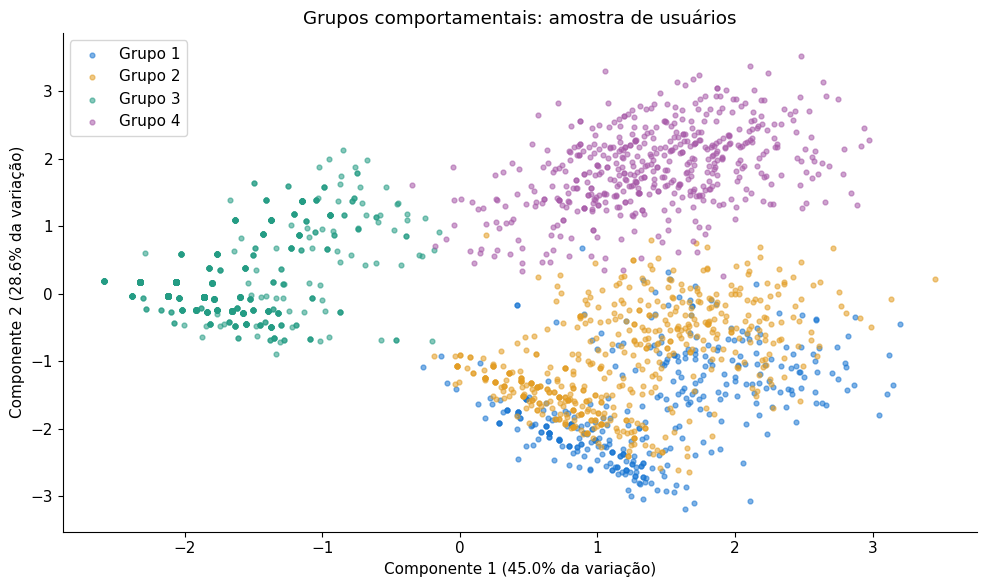

Variação representada no plano: 73.5%


In [11]:
pca = PCA(n_components=2)
coordenadas = pca.fit_transform(X)
variancia_pca = pca.explained_variance_ratio_
indices_grafico = np.random.default_rng(15).choice(len(X), min(2500, len(X)), replace=False)
fig, ax = plt.subplots(figsize=(10, 6))
for grupo in range(k_escolhido):
    pontos = indices_grafico[modelo_kmeans.labels_[indices_grafico] == grupo]
    ax.scatter(coordenadas[pontos, 0], coordenadas[pontos, 1], s=12, alpha=.55, color=CORES[grupo], label=f'Grupo {grupo + 1}')
ax.set(xlabel=f'Componente 1 ({variancia_pca[0]:.1%} da variação)',
       ylabel=f'Componente 2 ({variancia_pca[1]:.1%} da variação)',
       title='Grupos comportamentais: amostra de usuários')
ax.legend()
plt.tight_layout()
plt.show()
print(f'Variação representada no plano: {variancia_pca.sum():.1%}')

## 9. Entrada de um novo usuário

Informe seis características de um perfil fictício. A transformação usará as medianas e a escala aprendidas anteriormente. O K-means atribuirá o perfil ao centro mais próximo, sem refazer os grupos.

A distância ao centro não é uma probabilidade. Um usuário muito diferente dos demais ainda receberá um grupo, por isso vale conferir a distância e o perfil médio correspondente. Uma contagem muito acima do intervalo observado exige cuidado na interpretação.

In [12]:
def transformar_novos(dados):
    preenchidos = pd.DataFrame(imputador.transform(dados[variaveis]), columns=variaveis)
    preenchidos[colunas_log] = np.log1p(preenchidos[colunas_log])
    return padronizador.transform(preenchidos)

def ler_inteiro(pergunta, minimo=0, maximo=None):
    while True:
        try:
            numero = float(input(pergunta).replace(',', '.'))
            if not np.isfinite(numero) or numero % 1 != 0 or numero < minimo:
                raise ValueError
            if maximo is not None and numero > maximo:
                raise ValueError
            return int(numero)
        except ValueError:
            limite = f' entre {minimo} e {maximo}' if maximo is not None else f' a partir de {minimo}'
            print(f'Digite um número inteiro{limite}.')

novo_usuario = pd.DataFrame([{
    'publicacoes_30d': ler_inteiro('Publicações em 30 dias: '),
    'comentarios_30d': ler_inteiro('Comentários em 30 dias: '),
    'compartilhamentos_30d': ler_inteiro('Compartilhamentos em 30 dias: '),
    'curtidas_recebidas_30d': ler_inteiro('Curtidas recebidas em 30 dias: '),
    'diversidade_temas': ler_inteiro('Quantidade de temas (1 a 12): ', 1, 12),
    'frequencia_semanal': ler_inteiro('Dias ativos por semana (0 a 7): ', 0, 7)
}])
novo_X = transformar_novos(novo_usuario)
novo_grupo = int(modelo_kmeans.predict(novo_X)[0]) + 1
distancia_nova = float(modelo_kmeans.transform(novo_X).min())
distancias_treino = np.linalg.norm(X - modelo_kmeans.cluster_centers_[modelo_kmeans.labels_], axis=1)
referencia_distancia = np.quantile(distancias_treino[modelo_kmeans.labels_ == novo_grupo - 1], .95)
print(f'Grupo atribuído: {novo_grupo}')
print(f'Distância ao centro: {distancia_nova:.2f}')
if distancia_nova > referencia_distancia:
    print('A distância supera a de 95% dos usuários deste grupo. Examine o perfil antes de interpretá-lo.')
display(pd.concat([novo_usuario.rename(index={0:'Novo usuário'}),
                   perfil_grupos.loc[[novo_grupo]].rename(index={novo_grupo:'Média do grupo'})]).round(2))

Publicações em 30 dias: 60
Comentários em 30 dias: 37
Compartilhamentos em 30 dias: 49
Curtidas recebidas em 30 dias: 789
Quantidade de temas (1 a 12): 30
Digite um número inteiro entre 1 e 12.
Quantidade de temas (1 a 12): 6
Dias ativos por semana (0 a 7): 7
Grupo atribuído: 4
Distância ao centro: 10.35
A distância supera a de 95% dos usuários deste grupo. Examine o perfil antes de interpretá-lo.


,publicacoes_30d,comentarios_30d,compartilhamentos_30d,curtidas_recebidas_30d,diversidade_temas,frequencia_semanal
Novo usuário,60.00,37.00,49.00,789.00,6.00,7.00
Média do grupo,9.51,0.56,0.36,4.02,2.99,5.92


## 10. Conexões e comunidades

Agora mudamos a pergunta. Para o Louvain, cada usuário vira um nó e cada conexão vira uma aresta. Vamos somar as interações entre o mesmo par para formar o peso da conexão.

Neste exercício, trataremos a rede como **não direcionada**. Interações de A para B e de B para A contribuem para a mesma conexão. Também daremos o mesmo peso a cada evento, independentemente do tipo. São escolhas da análise, que poderiam mudar em outro estudo.

In [13]:
interacoes = interacoes_brutas.drop_duplicates('interacao_id').copy()
for coluna in ['usuario_origem', 'usuario_destino']:
    interacoes[coluna] = interacoes[coluna].astype('string').str.strip().str.upper()
ids_validos = set(resultado['usuario_id'])
validas = (interacoes['usuario_origem'].isin(ids_validos)
           & interacoes['usuario_destino'].isin(ids_validos)
           & interacoes['usuario_origem'].ne(interacoes['usuario_destino']))
interacoes = interacoes.loc[validas].copy()
pares = np.sort(interacoes[['usuario_origem', 'usuario_destino']].to_numpy(dtype=str), axis=1)
conexoes = pd.DataFrame(pares, columns=['usuario_a', 'usuario_b']).value_counts().rename('peso').reset_index()

rede = nx.Graph()
rede.add_nodes_from(resultado['usuario_id'])
rede.add_weighted_edges_from(conexoes[['usuario_a', 'usuario_b', 'peso']].itertuples(index=False, name=None), weight='peso')
print('Nós:', rede.number_of_nodes())
print('Conexões distintas:', rede.number_of_edges())
print('Eventos representados pelos pesos:', int(rede.size(weight='peso')))
print('Usuários sem conexão:', nx.number_of_isolates(rede))

Nós: 50000
Conexões distintas: 249564
Eventos representados pelos pesos: 250000
Usuários sem conexão: 0


## 11. Louvain

O Louvain procura partes da rede que concentram conexões entre seus próprios integrantes. Começa com os usuários separados e testa mudanças de comunidade. Quando uma mudança melhora a organização das conexões, ele a mantém. Depois, trata cada comunidade como uma unidade maior e repete a busca.

A **modularidade** avalia quanto as conexões se concentram dentro das comunidades, além do esperado em uma rede de referência que considera a atividade de cada nó. Uma modularidade mais alta favorece essa divisão quando comparamos a mesma rede e a mesma configuração. O valor não representa uma porcentagem de acertos.

Não informamos uma quantidade de comunidades. Usaremos resolução 1, que controla o nível de detalhe da divisão. Depois, repetiremos a busca com outros inícios para verificar se o resultado depende muito da ordem de análise dos nós.

In [14]:
comunidades = nx.community.louvain_communities(rede, weight='peso', resolution=1, seed=42)
comunidades = sorted(comunidades, key=lambda grupo: (-len(grupo), min(grupo)))
mapa_comunidades = {usuario: numero for numero, grupo in enumerate(comunidades, start=1) for usuario in grupo}
resultado['comunidade_louvain'] = resultado['usuario_id'].map(mapa_comunidades)
modularidade = nx.community.modularity(rede, comunidades, weight='peso', resolution=1)
print('Comunidades encontradas:', len(comunidades))
print(f'Modularidade: {modularidade:.3f}')
display(resultado['comunidade_louvain'].value_counts().sort_index().rename('Usuários').to_frame())

Comunidades encontradas: 8
Modularidade: 0.796


,Usuários
comunidade_louvain,
1,6287
2,6283
3,6266
4,6265
5,6255
6,6226
7,6224
8,6194


### 11.1. A divisão em comunidades ficou consistente?

Vamos verificar quanto das interações permanece dentro das comunidades e repetir o Louvain com duas outras sementes. Para essa comparação, a rede, os pesos e a resolução continuam iguais.

Uma grande concentração de interações internas ajuda a descrever a divisão, mas depende do tamanho das comunidades. Por isso, lemos esse resultado junto com a modularidade. A concordância entre as repetições mostra se a ordem de análise dos nós mudou bastante o resultado.

A repetição na rede completa pode levar alguns minutos. Os resultados desta execução já estão apresentados abaixo.

In [15]:
peso_interno = sum(dados['peso'] for a, b, dados in rede.edges(data=True)
                   if mapa_comunidades[a] == mapa_comunidades[b])
proporcao_interna = peso_interno / rede.size(weight='peso')
ordem_usuarios = resultado['usuario_id'].tolist()
referencia_louvain = resultado['comunidade_louvain'].to_numpy()
repeticoes_louvain = []
for semente in [7, 21]:
    novos_grupos = nx.community.louvain_communities(rede, weight='peso', resolution=1, seed=semente)
    mapa = {usuario: grupo for grupo, membros in enumerate(novos_grupos) for usuario in membros}
    novos_rotulos = [mapa[usuario] for usuario in ordem_usuarios]
    repeticoes_louvain.append({
        'Semente': semente, 'Comunidades': len(novos_grupos),
        'Modularidade': nx.community.modularity(rede, novos_grupos, weight='peso', resolution=1),
        'Concordância com a divisão original (ARI)': adjusted_rand_score(referencia_louvain, novos_rotulos)})
estabilidade_louvain = pd.DataFrame(repeticoes_louvain)
print(f'Interações dentro das comunidades: {proporcao_interna:.1%}')
display(estabilidade_louvain.round(4))

Interações dentro das comunidades: 92.1%


,Semente,Comunidades,Modularidade,Concordância com a divisão original (ARI)
0,7,8,0.79,0.87
1,21,8,0.80,0.87


### 11.2. Conclusão sobre o Louvain

**O resultado foi bom para explorar a estrutura desta rede, mas a composição das comunidades não ficou totalmente estável.** Na primeira execução, encontramos **8 comunidades**, modularidade de **0,796** e **92,1%** das interações dentro das próprias comunidades. Em conjunto, esses resultados mostram uma concentração expressiva de conexões internas.

As duas repetições também encontraram oito comunidades e modularidades próximas. Entretanto, a concordância com a primeira divisão ficou entre **0,873 e 0,876**, abaixo de uma correspondência completa. A estrutura geral se manteve, mas parte dos usuários mudou de comunidade. A concordância também é um índice, sem representar uma porcentagem de acertos.

Isso permite estudar a organização geral da rede, mas recomenda examinar com cuidado os usuários cuja atribuição muda entre execuções. Uma modularidade alta, sozinha, não prova que cada usuário tem uma comunidade definitiva. Os grupos indicam conexões e não permitem concluir que seus integrantes compartilham as mesmas opiniões.

*Esta leitura corresponde à rede e à resolução utilizadas nesta execução. Silhueta e modularidade avaliam aspectos diferentes, portanto não usamos seus valores para declarar um vencedor entre K-means e Louvain.*

## 12. Leitura da rede

Desenhar todos os nós ao mesmo tempo esconderia as conexões. Vamos selecionar até 40 usuários de cada uma das três maiores comunidades, começando por conexões entre elas. É um recorte intencional para observar as relações, não uma amostra representativa. As cores indicam os resultados obtidos na rede completa.

Cada ponto representa um usuário e cada linha indica uma conexão observada. A posição dos pontos vem de um algoritmo de desenho. Os eixos não representam frequência, opinião ou localização geográfica. O recorte omite muitas conexões e não serve para estimar o tamanho das comunidades. Partes da mesma comunidade podem aparecer separadas porque os caminhos entre elas ficaram fora do recorte.

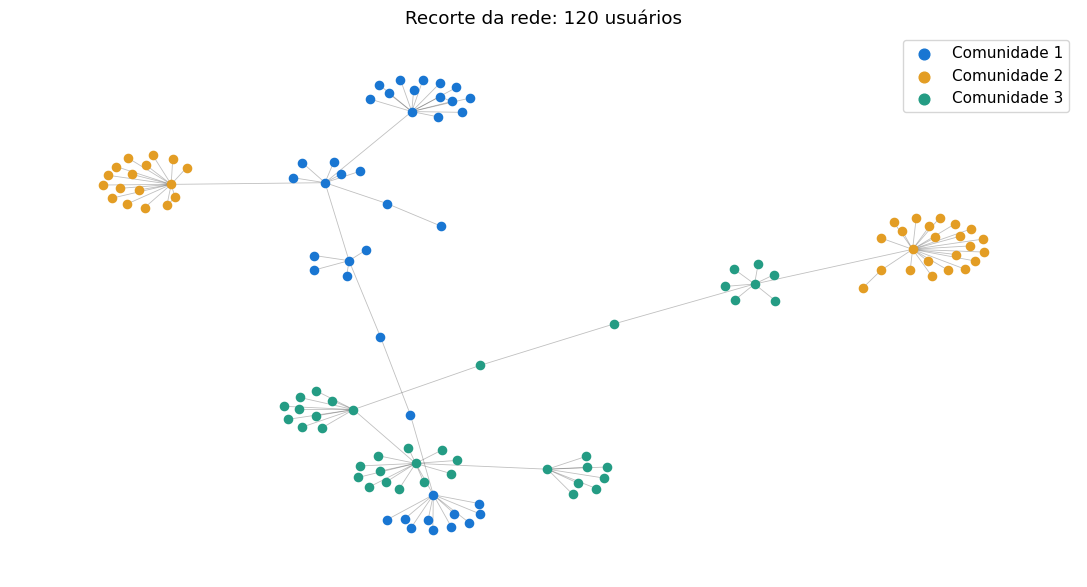

In [16]:
grupos_visiveis = [1, 2, 3]
sementes = {g: set() for g in grupos_visiveis}
for g1, g2 in [(1, 2), (2, 3), (1, 3)]:
    ponte = next(((a, b) for a, b in rede.edges
                  if {mapa_comunidades[a], mapa_comunidades[b]} == {g1, g2}), None)
    if ponte:
        for usuario in ponte:
            sementes[mapa_comunidades[usuario]].add(usuario)
selecionados = set()
for grupo in grupos_visiveis:
    membros = set(sementes[grupo]) or {min(comunidades[grupo - 1])}
    fila = sorted(membros)
    while fila and len(membros) < 40:
        atual = fila.pop(0)
        for vizinho in sorted(rede.neighbors(atual)):
            if mapa_comunidades[vizinho] == grupo and vizinho not in membros:
                membros.add(vizinho)
                fila.append(vizinho)
                if len(membros) == 40:
                    break
    selecionados.update(membros)
recorte = rede.subgraph(sorted(selecionados)).copy()
posicoes = nx.spring_layout(recorte, seed=42, weight='peso')
fig, ax = plt.subplots(figsize=(11, 6))
nx.draw_networkx_edges(recorte, posicoes, alpha=.25, width=.6, ax=ax)
for grupo in sorted({mapa_comunidades[u] for u in recorte}):
    membros = [u for u in recorte if mapa_comunidades[u] == grupo]
    nx.draw_networkx_nodes(recorte, posicoes, nodelist=membros, node_size=35,
                           node_color=CORES[(grupo - 1) % len(CORES)], label=f'Comunidade {grupo}', ax=ax)
ax.set_title(f'Recorte da rede: {len(recorte)} usuários')
ax.legend(markerscale=1.3)
ax.axis('off')
plt.tight_layout()
plt.show()

## 13. Comparação das duas análises

Vamos cruzar o grupo de comportamento com a comunidade de conexão. Cada linha abaixo soma 100% e mostra como os usuários de um grupo do K-means se distribuem entre as comunidades.

Se um grupo aparece em várias comunidades, isso mostra que o mesmo padrão de atividade ocorre em diferentes partes da rede. Uma comunidade também pode reunir usuários que publicam, comentam e compartilham em proporções distintas.

In [17]:
cruzamento = pd.crosstab(resultado['grupo_kmeans'], resultado['comunidade_louvain'], normalize='index') * 100
display(cruzamento.round(1))

grupo_exemplo = resultado['grupo_kmeans'].mode().iloc[0]
exemplos_comparacao = (resultado[resultado['grupo_kmeans'] == grupo_exemplo]
                      .drop_duplicates('comunidade_louvain')
                      .head(2)[['usuario_id', 'grupo_kmeans', 'comunidade_louvain'] + variaveis])
display(exemplos_comparacao)

resultado.to_csv('Aula_15_Resultados.csv', sep=';', decimal=',', index=False, encoding='utf-8-sig')
print('Resultados salvos em Aula_15_Resultados.csv.')

comunidade_louvain,1,2,3,4,5,6,7,8
grupo_kmeans,,,,,,,,
1,12.30,12.80,12.40,12.70,12.20,12.20,12.50,12.70
2,13.00,11.70,12.20,12.40,12.80,12.30,13.10,12.50
3,12.40,12.90,12.60,12.60,12.50,12.80,12.10,12.20
4,12.70,12.60,12.90,12.30,12.50,12.20,12.50,12.40


,usuario_id,grupo_kmeans,comunidade_louvain,publicacoes_30d,comentarios_30d,compartilhamentos_30d,curtidas_recebidas_30d,diversidade_temas,frequencia_semanal
0,U00001,3,6,0.00,0.00,0.00,0.00,1.00,3.00
3,U00004,3,1,1.00,0.00,0.00,1.00,2.00,1.00


Resultados salvos em Aula_15_Resultados.csv.


## 14. Discussão

1. Que evidências sustentam a escolha de quatro grupos? O que a silhueta permite concluir e o que ela não permite?
2. Qual grupo apresenta maior frequência de comentários? Essa diferença também aparece na quantidade de publicações?
3. Há um grupo comportamental concentrado em uma única comunidade? Use a tabela de cruzamento para justificar.
4. O que mudaria se o número de publicações fosse a única entrada do K-means?
5. Uma comunidade de contas permite concluir que seus integrantes concordam entre si? Quais dados faltariam para avaliar isso?

Na comunicação institucional, essas análises podem ajudar a descrever formas de participação e caminhos de interação. Para saber quais assuntos circulam, seria necessário analisar os conteúdos. O exercício atual trabalha com atividade e conexões.

### Referências

- [K-means: funcionamento e limitações — scikit-learn](https://scikit-learn.org/stable/modules/clustering.html#k-means)
- [Parâmetros do KMeans — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
- [Coeficiente de silhueta — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)
- [PCA — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
- [Louvain — NetworkX](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.community.louvain.louvain_communities.html)
- [Método original de Louvain — Blondel e colaboradores](https://arxiv.org/abs/0803.0476)
- [Leitura do gráfico de silhueta — scikit-learn](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html)
- [Concordância entre agrupamentos — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html)